# Nested dichotomies in Python with ndscape

The code for the tutorial at https://res-lucid.github.io/ndscape-plots/tutorial/. Section numbers follow the page.

```
pip install "ndscape[plot,spatial]" torch
```

## 1. Data and binary classifier

In [1]:
import numpy as np
from sklearn.datasets import fetch_openml
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import train_test_split
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
import ndscape as nds

GLASS_NAMES = {"build wind float": "building (float)", "build wind non-float": "building (non float)",
               "vehic wind float": "vehicle (float)"}


def load(name):
    X, y = fetch_openml(name, version=1, return_X_y=True, as_frame=True, parser="liac-arff")
    return X.to_numpy(float), y.astype(str)


X, y = load("glass")
y = y.replace(GLASS_NAMES).to_numpy(dtype=object)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, stratify=y, random_state=0)
classes = sorted(set(y_train))
lr = make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000))

## 2. A three-class example

In [2]:
from sklearn.model_selection import StratifiedKFold

FOLDS = 3


def name(side):
    return side[0] if len(side) == 1 else "(" + ", ".join(side) + ")"


def show(tree):
    splits = {frozenset(left + right): (left, right) for left, right in tree}

    def lines(group, prefix):
        out = []
        kids = [side for side in splits[frozenset(group)] if len(side) > 1]
        for i, kid in enumerate(kids):
            last = i == len(kids) - 1
            left, right = splits[frozenset(kid)]
            out.append(f"{prefix}{'└─' if last else '├─'} {name(left)} vs {name(right)}")
            out += lines(kid, prefix + ("   " if last else "│  "))
        return out

    left, right = tree[0]
    return "\n".join([f"{name(left)} vs {name(right)}"] + lines(left + right, ""))


def cv_scores(tree, classes, X, y, base, folds):
    scores = [nds.ND(tree, classes).fit(X[tr], y[tr], base=base).score(X[va], y[va]) for tr, va in folds]
    return np.mean([s["accuracy"] for s in scores]), np.mean([s["logloss"] for s in scores])


three = ["building (float)", "building (non float)", "headlamps"]
keep = np.isin(y_train, three)
X3, y3 = X_train[keep], y_train[keep]
folds3 = list(StratifiedKFold(FOLDS, shuffle=True, random_state=0).split(X3, y3))
print("first training sample is", y3[0])
for tree in nds.all_trees(three):
    nd = nds.ND(tree, three).fit(X3, y3, base=lr)
    print(show(tree))
    for (left, right), model in nd.models.items():
        print(f"  P({name(left)} | x) = {model.predict_proba(X3[:1])[0, 0]:.3f}")
    print("  P(class | x):", ", ".join(f"{c} {p:.3f}" for c, p in zip(three, nd.predict_proba(X3[:1])[0])))
    print("  cross-validated accuracy %.3f, log loss %.3f\n" % cv_scores(tree, three, X3, y3, lr, folds3))

first training sample is building (float)
(building (non float), headlamps) vs building (float)
└─ building (non float) vs headlamps
  P((building (non float), headlamps) | x) = 0.788
  P(building (non float) | x) = 0.992
  P(class | x): building (float) 0.212, building (non float) 0.781, headlamps 0.006
  cross-validated accuracy 0.746, log loss 0.569

(building (float), building (non float)) vs headlamps
└─ building (float) vs building (non float)
  P((building (float), building (non float)) | x) = 0.996
  P(building (float) | x) = 0.192
  P(class | x): building (float) 0.191, building (non float) 0.805, headlamps 0.004
  cross-validated accuracy 0.754, log loss 0.560

(building (float), headlamps) vs building (non float)
└─ building (float) vs headlamps
  P((building (float), headlamps) | x) = 0.267
  P(building (float) | x) = 0.989
  P(class | x): building (float) 0.264, building (non float) 0.733, headlamps 0.003
  cross-validated accuracy 0.705, log loss 0.657



## 3. The map

In [3]:
trees, coords = nds.embed_trees(classes)

C:\Users\maxdi\AppData\Local\Temp\claude\C--Users-maxpc-Documents-code-business\8e1fa1cf-0d34-4109-9429-8f82e0f52d09\scratchpad\nbenv\Lib\site-packages\sklearn\manifold\_mds.py:735: FutureWarning: The default value of `init` will change from 'random' to 'classical_mds' in 1.10. To suppress this warning, provide some value of `init`.
  warnings.warn(
C:\Users\maxdi\AppData\Local\Temp\claude\C--Users-maxpc-Documents-code-business\8e1fa1cf-0d34-4109-9429-8f82e0f52d09\scratchpad\nbenv\Lib\site-packages\sklearn\manifold\_mds.py:752: FutureWarning: The `dissimilarity` parameter is deprecated and will be removed in 1.10. Use `metric` instead.
  warnings.warn(


## 4. Scores for every ND

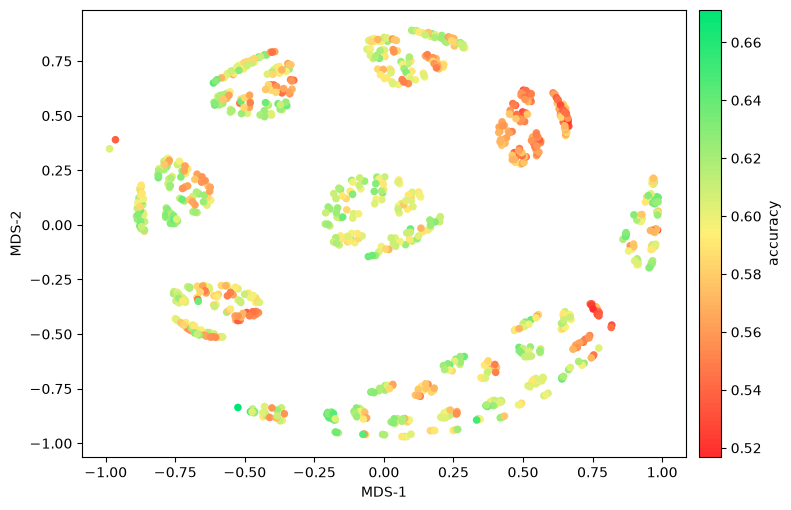

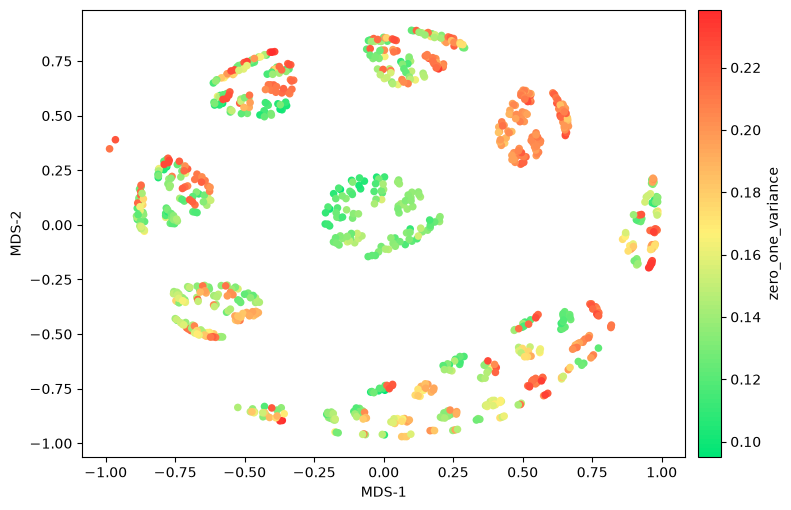

In [4]:
import matplotlib.pyplot as plt
from bokeh.io import save
from bokeh.models import HoverTool, LinearColorMapper
from joblib import Parallel, delayed
from ndscape.plot import BRIGHT
from sklearn.utils import resample

B = 50


def bootstrap_variance(tree, classes, X, y, X_eval, base, resamples):
    probs = np.stack([nds.ND(tree, classes).fit(X[i], y[i], base=base).predict_proba(X_eval) for i in resamples])
    votes = (probs.argmax(axis=2)[:, :, None] == np.arange(len(classes))).sum(axis=0)
    return 1 - votes.max(axis=1).mean() / len(resamples), probs.var(axis=0, ddof=1).mean()


def score_all(trees, coords, classes, X_train, y_train, X_test, base):
    folds = list(StratifiedKFold(FOLDS, shuffle=True, random_state=0).split(X_train, y_train))
    cv = Parallel(n_jobs=-1)(delayed(cv_scores)(t, classes, X_train, y_train, base, folds) for t in trees)
    rows = [{"tree": t, "coord": c, "accuracy": a, "logloss": ll} for t, c, (a, ll) in zip(trees, coords, cv)]
    # stratified, so every class is in every resample; the same resamples for every ND
    resamples = [resample(np.arange(len(y_train)), stratify=y_train, random_state=b) for b in range(B)]
    boot = Parallel(n_jobs=-1)(delayed(bootstrap_variance)(t, classes, X_train, y_train, X_test, base, resamples)
                               for t in trees)
    for r, (zero_one, prob) in zip(rows, boot):
        r["zero_one_variance"] = zero_one
        r["probability_variance"] = prob
    return rows


def map_png(rows, metric, path, cmap=BRIGHT):
    coords = np.array([r["coord"] for r in rows])
    fig, ax = plt.subplots(figsize=(8, 5.2))
    sc = ax.scatter(coords[:, 0], coords[:, 1], c=[r[metric] for r in rows], cmap=cmap, s=30, linewidths=0)
    fig.colorbar(sc, ax=ax, fraction=0.046, pad=0.02).set_label(metric)
    ax.set_xlabel("MDS-1")
    ax.set_ylabel("MDS-2")
    fig.tight_layout()
    fig.savefig(path, dpi=200)
    plt.show()


def variance_html(rows, path):
    p = nds.plot_interactive(rows, metric="zero_one_variance", path=path)
    mapper = p.select_one(LinearColorMapper)
    mapper.palette = mapper.palette[::-1]
    p.select_one(HoverTool).tooltips.append(("zero-one variance", "@value{0.000}"))
    save(p, path)


rows = score_all(trees, coords, classes, X_train, y_train, X_test, lr)
map_png(rows, "accuracy", "glass_lr_accuracy.png")
nds.plot_interactive(rows, metric="accuracy", path="glass_lr_accuracy.html")
map_png(rows, "zero_one_variance", "glass_lr_zero_one_variance.png", BRIGHT.reversed())
variance_html(rows, "glass_lr_zero_one_variance.html")

## 5. Reading the map

In [5]:
from collections import defaultdict


def root_split(tree):
    left, right = tree[0]
    small = min(left, right, key=len)
    return f"{small[0]} vs rest" if len(small) == 1 else f"{len(small)} vs {len(left) + len(right) - len(small)} classes"


def by_root_split(rows, metric):
    groups = defaultdict(list)
    for r in rows:
        groups[root_split(r["tree"])].append(r[metric])
    for split, v in sorted(groups.items(), key=lambda kv: -np.mean(kv[1])):
        print(f"  {split:30} {len(v):4} NDs  mean {np.mean(v):.5f}  sd across NDs {np.std(v):.4f}")
    return groups


for metric in ("accuracy", "logloss", "zero_one_variance", "probability_variance"):
    values = np.array([r[metric] for r in rows])
    print(f"{metric}: {values.min():.5f} to {values.max():.5f}, Moran's I",
          nds.spatial_autocorrelation(values, coords))
print("cross-validated accuracy by root split")
groups = by_root_split(rows, "accuracy")
print("zero-one variance by root split")
by_root_split(rows, "zero_one_variance")

accuracy: 0.51687 to 0.67116, Moran's I {'I': np.float64(0.33113550099035216), 'p_sim': np.float64(0.001)}
logloss: 1.00080 to 1.83128, Moran's I {'I': np.float64(0.2613993356622242), 'p_sim': np.float64(0.001)}
zero_one_variance: 0.09508 to 0.23846, Moran's I {'I': np.float64(0.2729924428024736), 'p_sim': np.float64(0.001)}


probability_variance: 0.00293 to 0.00648, Moran's I {'I': np.float64(0.3760786687588075), 'p_sim': np.float64(0.001)}
cross-validated accuracy by root split
  building (float) vs rest        105 NDs  mean 0.60653  sd across NDs 0.0151
  headlamps vs rest               105 NDs  mean 0.60597  sd across NDs 0.0233
  3 vs 3 classes                   90 NDs  mean 0.60279  sd across NDs 0.0264
  2 vs 4 classes                  225 NDs  mean 0.59782  sd across NDs 0.0279
  vehicle (float) vs rest         105 NDs  mean 0.59759  sd across NDs 0.0273
  tableware vs rest               105 NDs  mean 0.59473  sd across NDs 0.0214
  containers vs rest              105 NDs  mean 0.58755  sd across NDs 0.0237
  building (non float) vs rest    105 NDs  mean 0.55850  sd across NDs 0.0153
zero-one variance by root split
  building (non float) vs rest    105 NDs  mean 0.20296  sd across NDs 0.0100
  3 vs 3 classes                   90 NDs  mean 0.16987  sd across NDs 0.0375
  tableware vs rest            

defaultdict(list,
            {'building (float) vs rest': [np.float64(0.13230769230769224),
              np.float64(0.1384615384615384),
              np.float64(0.13784615384615373),
              np.float64(0.14123076923076927),
              np.float64(0.13476923076923075),
              np.float64(0.1406153846153846),
              np.float64(0.13630769230769235),
              np.float64(0.13692307692307693),
              np.float64(0.13384615384615384),
              np.float64(0.14123076923076927),
              np.float64(0.13538461538461533),
              np.float64(0.13692307692307693),
              np.float64(0.1295384615384616),
              np.float64(0.13230769230769224),
              np.float64(0.1350769230769231),
              np.float64(0.11784615384615382),
              np.float64(0.12307692307692308),
              np.float64(0.1184615384615384),
              np.float64(0.13230769230769224),
              np.float64(0.13476923076923075),
              np.fl

## 6. Selecting an ND

The two selection rules use the training set only, and their test scores are the final evaluation.

In [6]:
from scipy.stats import binomtest

best = max(rows, key=lambda r: r["accuracy"])
family = max(groups, key=lambda k: np.mean(groups[k]))
chosen = max((r for r in rows if root_split(r["tree"]) == family), key=lambda r: r["accuracy"])
correct = []
for label, r in (("highest cross-validated accuracy", best), (f"best ND in '{family}'", chosen)):
    correct.append(nds.ND(r["tree"], classes).fit(X_train, y_train, base=lr).predict(X_test) == y_test)
    k, n = int(correct[-1].sum()), len(y_test)
    ci = binomtest(k, n).proportion_ci(method="wilson")
    print(f"{label}: cv {r['accuracy']:.3f}, test {k}/{n} = {k / n:.3f}, 95% CI {ci.low:.3f} to {ci.high:.3f}")
    print(show(r["tree"]), "\n")
a, b = correct
only_a, only_b = int((a & ~b).sum()), int((~a & b).sum())
print(f"right under one ND only: {only_a} and {only_b}, exact McNemar p = {binomtest(only_a, only_a + only_b).pvalue:.3f}")

highest cross-validated accuracy: cv 0.671, test 37/65 = 0.569, 95% CI 0.448 to 0.682
(building (float), tableware, vehicle (float)) vs (building (non float), containers, headlamps)
├─ (building (float), tableware) vs vehicle (float)
│  └─ building (float) vs tableware
└─ (building (non float), containers) vs headlamps
   └─ building (non float) vs containers 

best ND in 'building (float) vs rest': cv 0.637, test 39/65 = 0.600, 95% CI 0.479 to 0.710
(building (non float), containers, headlamps, tableware, vehicle (float)) vs building (float)
└─ (building (non float), tableware, vehicle (float)) vs (containers, headlamps)
   ├─ (building (non float), tableware) vs vehicle (float)
   │  └─ building (non float) vs tableware
   └─ containers vs headlamps 

right under one ND only: 5 and 7, exact McNemar p = 0.774


Exploratory: the test accuracy of every ND. Choosing an ND from these numbers would need a fresh test set.

In [7]:
test = [nds.ND(r["tree"], classes).fit(X_train, y_train, base=lr).score(X_test, y_test)["accuracy"] for r in rows]
for split in groups:
    members = [t for r, t in zip(rows, test) if root_split(r["tree"]) == split]
    print(f"  test accuracy, {split:30} mean {np.mean(members):.3f}")

  test accuracy, building (float) vs rest       mean 0.627
  test accuracy, 2 vs 4 classes                 mean 0.575
  test accuracy, 3 vs 3 classes                 mean 0.566
  test accuracy, vehicle (float) vs rest        mean 0.566
  test accuracy, tableware vs rest              mean 0.582
  test accuracy, headlamps vs rest              mean 0.617
  test accuracy, containers vs rest             mean 0.560
  test accuracy, building (non float) vs rest   mean 0.540


## 7. A PyTorch model at each node

In [8]:
import torch
from sklearn.base import BaseEstimator, ClassifierMixin


class TorchMLP(ClassifierMixin, BaseEstimator):
    def __init__(self, width=512, depth=4, epochs=300, lr=1e-3):
        self.width = width
        self.depth = depth
        self.epochs = epochs
        self.lr = lr

    def fit(self, X, y):
        torch.manual_seed(0)
        X, y = torch.tensor(X, dtype=torch.float32), torch.tensor(y)
        dims = [X.shape[1]] + [self.width] * self.depth
        layers = [m for a, b in zip(dims, dims[1:]) for m in (torch.nn.Linear(a, b), torch.nn.ReLU())]
        self.net_ = torch.nn.Sequential(*layers, torch.nn.Linear(self.width, 2))
        opt = torch.optim.Adam(self.net_.parameters(), lr=self.lr)
        for _ in range(self.epochs):
            opt.zero_grad()
            torch.nn.functional.cross_entropy(self.net_(X), y).backward()
            opt.step()
        self.classes_ = np.array([0, 1])
        return self

    def predict_proba(self, X):
        with torch.no_grad():
            return torch.softmax(self.net_(torch.tensor(X, dtype=torch.float32)), dim=1).numpy()


mlp = make_pipeline(StandardScaler(), TorchMLP())
nd = nds.ND(chosen["tree"], classes).fit(X_train, y_train, base=mlp)
print(f"{len(nd.models)} torch models, {sum(p.numel() for m in nd.models.values() for p in m[-1].net_.parameters()):,} parameters")
folds = list(StratifiedKFold(FOLDS, shuffle=True, random_state=0).split(X_train, y_train))
print("cross-validated accuracy: logistic regression %.3f, torch MLP %.3f"
      % (chosen["accuracy"], cv_scores(chosen["tree"], classes, X_train, y_train, mlp, folds)[0]))

5 torch models, 3,970,570 parameters


cross-validated accuracy: logistic regression 0.637, torch MLP 0.671


## 8. Another dataset and binary classifier

C:\Users\maxdi\AppData\Local\Temp\claude\C--Users-maxpc-Documents-code-business\8e1fa1cf-0d34-4109-9429-8f82e0f52d09\scratchpad\nbenv\Lib\site-packages\sklearn\manifold\_mds.py:735: FutureWarning: The default value of `init` will change from 'random' to 'classical_mds' in 1.10. To suppress this warning, provide some value of `init`.
  warnings.warn(
C:\Users\maxdi\AppData\Local\Temp\claude\C--Users-maxpc-Documents-code-business\8e1fa1cf-0d34-4109-9429-8f82e0f52d09\scratchpad\nbenv\Lib\site-packages\sklearn\manifold\_mds.py:752: FutureWarning: The `dissimilarity` parameter is deprecated and will be removed in 1.10. Use `metric` instead.
  warnings.warn(


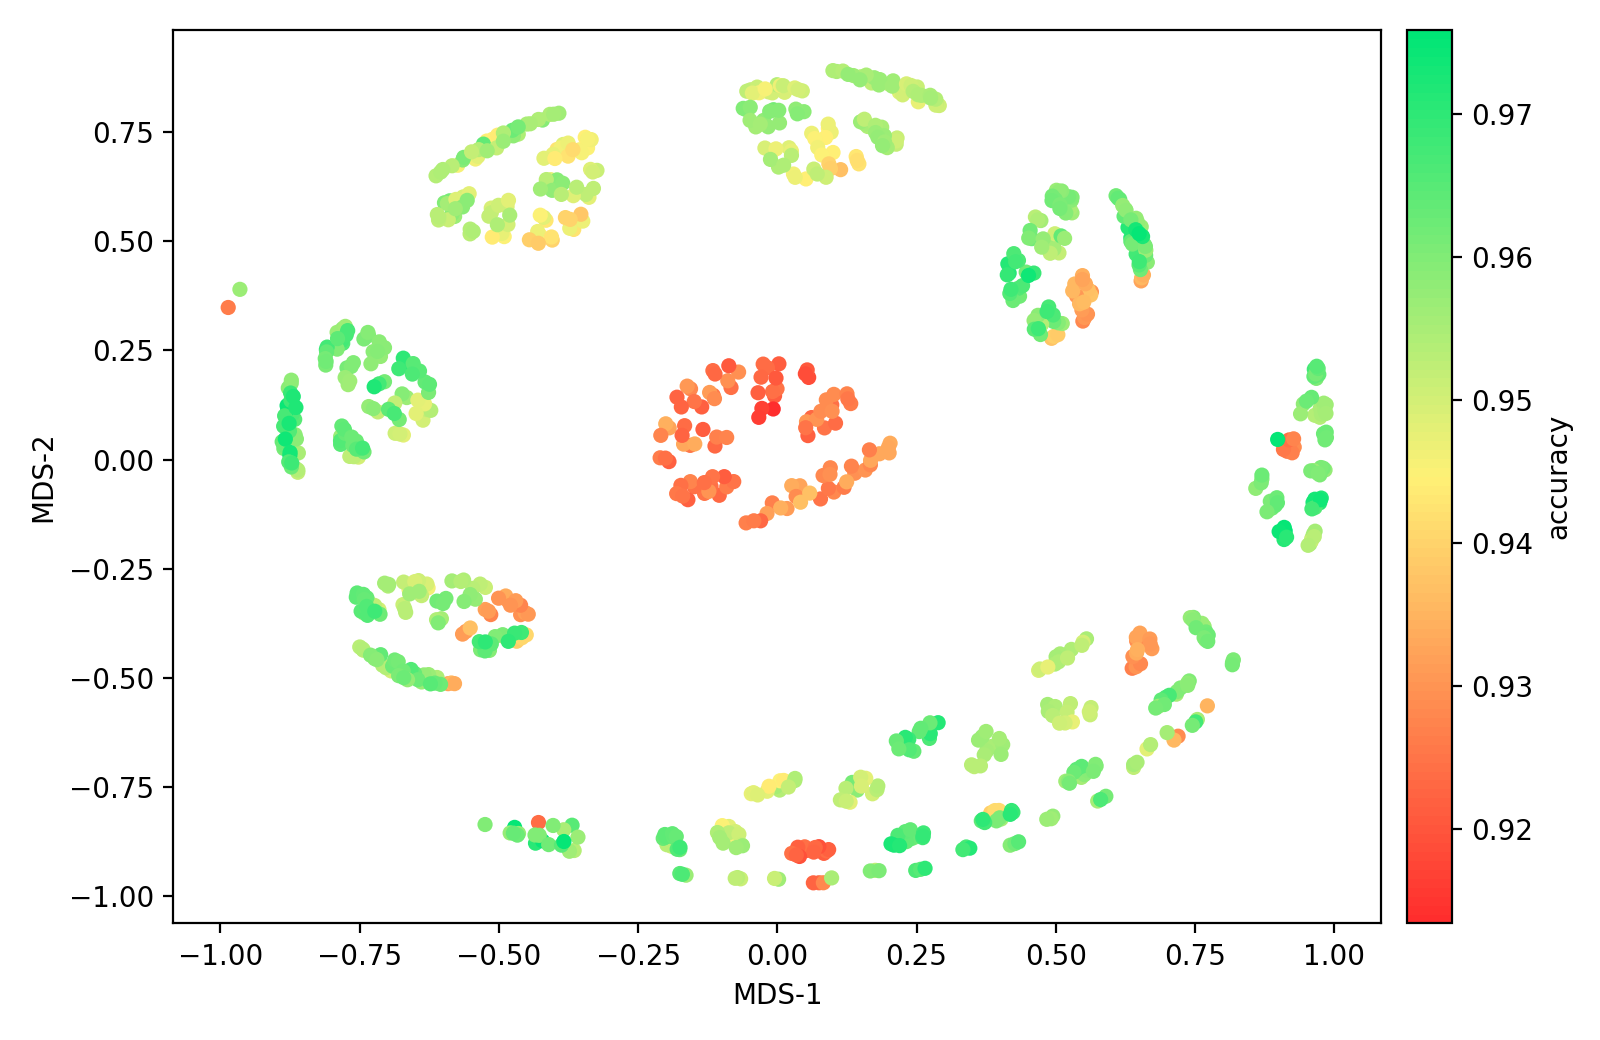

LDA accuracy: 0.91342 to 0.97587, Moran's I {'I': np.float64(0.5381025919472547), 'p_sim': np.float64(0.001)}
LDA zero_one_variance: 0.00590 to 0.02518, Moran's I {'I': np.float64(0.37767791169663667), 'p_sim': np.float64(0.001)}
LDA probability_variance: 0.00088 to 0.00195, Moran's I {'I': np.float64(0.35542884740701625), 'p_sim': np.float64(0.001)}
cross-validated accuracy by root split
  ethanol vs rest                 105 NDs  mean 0.96144  sd across NDs 0.0065
  3 vs 3 classes                   90 NDs  mean 0.95848  sd across NDs 0.0124
  acetone vs rest                 105 NDs  mean 0.95627  sd across NDs 0.0122
  2 vs 4 classes                  225 NDs  mean 0.95369  sd across NDs 0.0124
  ammonia vs rest                 105 NDs  mean 0.95331  sd across NDs 0.0115
  ethylene vs rest                105 NDs  mean 0.95191  sd across NDs 0.0050
  toluene vs rest                 105 NDs  mean 0.95064  sd across NDs 0.0059
  acetaldehyde vs rest            105 NDs  mean 0.92640  sd ac

In [9]:
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis

GAS_NAMES = {"1": "ethanol", "2": "ethylene", "3": "ammonia", "4": "acetaldehyde", "5": "acetone", "6": "toluene"}

X, y = load("gas-drift")
y = y.replace(GAS_NAMES).to_numpy(dtype=object)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, stratify=y, random_state=0)
classes = sorted(set(y_train))
lda = make_pipeline(StandardScaler(), LinearDiscriminantAnalysis())
trees, coords = nds.embed_trees(classes)
rows = score_all(trees, coords, classes, X_train, y_train, X_test, lda)
map_png(rows, "accuracy", "gas_lda_accuracy.png")
nds.plot_interactive(rows, metric="accuracy", path="gas_lda_accuracy.html")
for metric in ("accuracy", "zero_one_variance", "probability_variance"):
    values = np.array([r[metric] for r in rows])
    print(f"LDA {metric}: {values.min():.5f} to {values.max():.5f}, Moran's I",
          nds.spatial_autocorrelation(values, coords))
print("cross-validated accuracy by root split")
groups = by_root_split(rows, "accuracy")

Exploratory, as in section 6.

In [10]:
test = [nds.ND(r["tree"], classes).fit(X_train, y_train, base=lda).score(X_test, y_test)["accuracy"] for r in rows]
print("correlation of cross-validated and test accuracy over NDs:",
      round(np.corrcoef([r["accuracy"] for r in rows], test)[0, 1], 3))

correlation of cross-validated and test accuracy over NDs: 0.981
